In [2]:
import pandas as pd
df = pd.read_csv("C:\\Users\\Nagesh Chaudhary\\Desktop\\cropyy\\data\\Crop_recommendation.csv")
df.head()

,N,P,K,temperature,humidity,ph,rainfall,label
0,90,42,43,20.879744,82.002744,6.502985,202.935536,rice
1,85,58,41,21.770462,80.319644,7.038096,226.655537,rice
2,60,55,44,23.004459,82.320763,7.840207,263.964248,rice
3,74,35,40,26.491096,80.158363,6.980401,242.864034,rice
4,78,42,42,20.130175,81.604873,7.628473,262.717340,rice


In [3]:
import sys
print(sys.executable)

c:\Users\Nagesh Chaudhary\Desktop\cropyy\venv\Scripts\python.exe


In [3]:
print(df.shape)


(2200, 8)


In [4]:
print(df.isnull().sum())

N              0
P              0
K              0
temperature    0
humidity       0
ph             0
rainfall       0
label          0
dtype: int64


In [5]:
print(df["label"].value_counts())

label
rice           100
maize          100
chickpea       100
kidneybeans    100
pigeonpeas     100
mothbeans      100
mungbean       100
blackgram      100
lentil         100
pomegranate    100
banana         100
mango          100
grapes         100
watermelon     100
muskmelon      100
apple          100
orange         100
papaya         100
coconut        100
cotton         100
jute           100
coffee         100
Name: count, dtype: int64


In [6]:
df.describe()

,N,P,K,temperature,humidity,ph,rainfall
count,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000
mean,50.551818,53.362727,48.149091,25.616244,71.481779,6.469480,103.463655
std,36.917334,32.985883,50.647931,5.063749,22.263812,0.773938,54.958389
min,0.000000,5.000000,5.000000,8.825675,14.258040,3.504752,20.211267
25%,21.000000,28.000000,20.000000,22.769375,60.261953,5.971693,64.551686
50%,37.000000,51.000000,32.000000,25.598693,80.473146,6.425045,94.867624
75%,84.250000,68.000000,49.000000,28.561654,89.948771,6.923643,124.267508
max,140.000000,145.000000,205.000000,43.675493,99.981876,9.935091,298.560117


Matplotlib is building the font cache; this may take a moment.


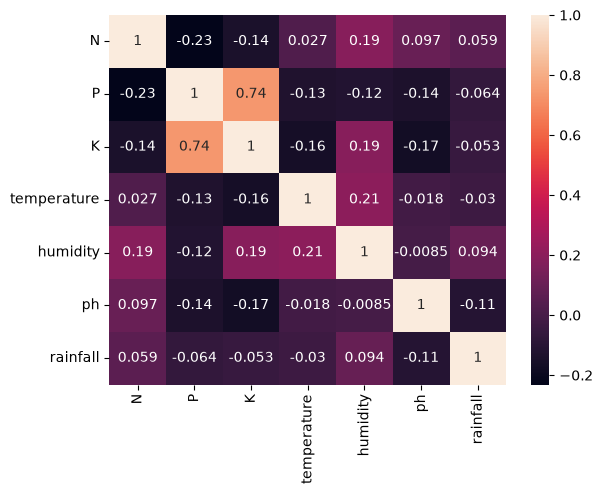

In [7]:
import seaborn as sns
import matplotlib.pyplot as plt
sns.heatmap(df.drop(columns="label").corr(), annot=True)
plt.show()

In [8]:
from sklearn.model_selection import train_test_split

X = df.drop(columns="label")   # inputs: N, P, K, temperature, humidity, ph, rainfall
y = df["label"]                # the answer: crop name

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

In [9]:
print(X_train.shape, X_test.shape)

(1760, 7) (440, 7)


In [10]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

models = {
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42),
}
for name, model in models.items():
    model.fit(X_train, y_train)
    print(name, accuracy_score(y_test, model.predict(X_test)))

Decision Tree 0.9795454545454545
Random Forest 0.9954545454545455


In [11]:
from sklearn.metrics import classification_report

best = models["Random Forest"]
print(classification_report(y_test, best.predict(X_test)))

              precision    recall  f1-score   support

       apple       1.00      1.00      1.00        20
      banana       1.00      1.00      1.00        20
   blackgram       1.00      0.95      0.97        20
    chickpea       1.00      1.00      1.00        20
     coconut       1.00      1.00      1.00        20
      coffee       1.00      1.00      1.00        20
      cotton       1.00      1.00      1.00        20
      grapes       1.00      1.00      1.00        20
        jute       0.95      1.00      0.98        20
 kidneybeans       1.00      1.00      1.00        20
      lentil       1.00      1.00      1.00        20
       maize       0.95      1.00      0.98        20
       mango       1.00      1.00      1.00        20
   mothbeans       1.00      1.00      1.00        20
    mungbean       1.00      1.00      1.00        20
   muskmelon       1.00      1.00      1.00        20
      orange       1.00      1.00      1.00        20
      papaya       1.00    

In [12]:
import numpy as np

probs = best.predict_proba(X_test.iloc[[0]])[0]
top3 = np.argsort(probs)[::-1][:3]
for i in top3:
    print(best.classes_[i], round(probs[i] * 100, 1), "%")

orange 97.0 %
pomegranate 3.0 %
rice 0.0 %


In [13]:
print(y_test.iloc[0])

orange


In [14]:
cols = ["temperature", "humidity", "ph", "rainfall"]
X2_train, X2_test = X_train[cols], X_test[cols]

model_lite = RandomForestClassifier(random_state=42)
model_lite.fit(X2_train, y_train)
print("Lite model accuracy:", accuracy_score(y_test, model_lite.predict(X2_test)))

Lite model accuracy: 0.9590909090909091


In [15]:

print(classification_report(y_test, model_lite.predict(X2_test)))

              precision    recall  f1-score   support

       apple       0.87      1.00      0.93        20
      banana       1.00      0.95      0.97        20
   blackgram       0.95      1.00      0.98        20
    chickpea       1.00      1.00      1.00        20
     coconut       1.00      1.00      1.00        20
      coffee       1.00      1.00      1.00        20
      cotton       0.91      1.00      0.95        20
      grapes       1.00      0.95      0.97        20
        jute       0.95      1.00      0.98        20
 kidneybeans       1.00      1.00      1.00        20
      lentil       0.95      1.00      0.98        20
       maize       1.00      1.00      1.00        20
       mango       0.95      1.00      0.98        20
   mothbeans       1.00      0.90      0.95        20
    mungbean       1.00      1.00      1.00        20
   muskmelon       1.00      1.00      1.00        20
      orange       0.84      0.80      0.82        20
      papaya       0.89    

In [16]:
pred = model_lite.predict(X2_test)
mask = (y_test == "pomegranate").values
print(pd.Series(pred[mask]).value_counts())

pomegranate    15
apple           3
orange          2
Name: count, dtype: int64


In [17]:
import joblib

joblib.dump(best, "../models/crop_model_full.joblib")
joblib.dump(model_lite, "../models/crop_model_lite.joblib")

['../models/crop_model_lite.joblib']

Full model: ~99%. Lite model (no NPK): 95%. Weakest crop in lite model is pomegranate (recall 0.75).

The lite model’s weakest crop is pomegranate (recall 0.75), mostly confused with apple and orange. Crops with overlapping climate need soil nutrient data to be told apart.”